# Predicting success for basketball players in the NBA
A range of different statistics are recorded for *rookie* (i.e. first year) basketball players over an NBA season.

In this notebook you will explore which features can be used to build a model to predict whether they will still be playing in the NBA 5 years later.

**notes**

binary classification: a model that sorts data into two sets based on the values of other features

binary features are those that can take exactly two values; 1 or 0, yes or no etc.

3 types of machine learning:
1. supervised
2. unsupervised
3. reinforcement

machine learning is an iterative process. we create a model, make small changes, and see if this is a better fit. we can then reject or keep the change we make

you can open the data set by pressing the 3 dots on the right side of the page. it gives you more info on the data

## Importing the libraries and data

In [1]:
# pandas for data analysis
import pandas as pd

# seaborn for visualisation
import seaborn as sns
sns.set_context("talk")

# seaborn has some unhelpful warnings at the moment
import warnings
warnings.filterwarnings("ignore", module="seaborn")

# Import functions from sklearn for building the model, training-testing split, visualising the model and metrics 
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Function to draw the model
def plot_decision_tree(tree_model):
    fig, ax = plt.subplots(figsize=(20,8))
    plot_tree(tree_model,  
        filled=True, 
        feature_names=input_features, 
        impurity=False,
        class_names=["No","Yes"], 
        proportion=True, 
        ax=ax)
    plt.show()

In [2]:
#import the data
nba_data = pd.read_csv('/kaggle/input/basketball/nba_data.csv')

# display the data to check it has imported
nba_data

,Name,GP,MIN,PTS,FGS,FGA,3PM,3PA,FTM,FTA,OREB,DREB,AST,STL,BLK,TOV,5Yrs
0,Brandon Ingram,36,27.4,7.4,2.6,7.6,0.5,2.1,1.6,2.3,0.7,3.4,1.9,0.4,0.4,1.3,0
1,Andrew Harrison,35,26.9,7.2,2.0,6.7,0.7,2.8,2.6,3.4,0.5,2.0,3.7,1.1,0.5,1.6,0
2,JaKarr Sampson,74,15.3,5.2,2.0,4.7,0.4,1.7,0.9,1.3,0.5,1.7,1.0,0.5,0.3,1.0,0
3,Malik Sealy,58,11.6,5.7,2.3,5.5,0.1,0.5,0.9,1.3,1.0,0.9,0.8,0.6,0.1,1.0,1
4,Matt Geiger,48,11.5,4.5,1.6,3.0,0.0,0.1,1.3,1.9,1.0,1.5,0.3,0.3,0.4,0.8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1303,Chris Smith,80,15.8,4.3,1.6,3.6,0.0,0.2,1.2,1.5,0.4,0.8,2.5,0.6,0.2,0.8,0
1304,Brent Price,68,12.6,3.9,1.5,4.1,0.1,0.7,0.8,1.0,0.4,1.1,2.3,0.8,0.0,1.3,1
1305,Marlon Maxey,43,12.1,5.4,2.2,3.9,0.0,0.0,1.0,1.6,1.5,2.3,0.3,0.3,0.4,0.9,0
1306,Litterial Green,52,12.0,4.5,1.7,3.8,0.0,0.2,1.2,1.8,0.2,0.4,2.2,0.4,0.1,0.8,1


This data set contains information about NBA basketball players between 1990 and 2016. Each row describes the performance of a basketball player during their first ('rookie') year. Performance statistics are per game.

There are 1,308 individual records, each representing an individual player.

Features:
* **Name**: *Player name*
* **GP**: *Number of games played*
* **MIN**: *Mean number of minutes played*
* **PTS**: *Mean number of points scored*
* **FGS**: *Mean number of field goals scored*
* **FGA**: *Mean number of field goals attempted*
* **3PM**: *Mean number of 3-point shots made*
* **3PA**: *Mean number of 3-point shots attempted*
* **FTM**: *Mean number of free throws made*
* **FTA**: *Mean number of free throws attempted*
* **OREB**: *Mean number of offensive rebounds*
* **DREB**: *Mean number of defensive rebounds*
* **AST**: *Mean number of assists*
* **STL**: *Mean number of steals*
* **BLK**: *Mean number of blocks*
* **TOV**: *Mean number of turnovers*
* **5Yrs**: *Whether the player was still playing in the NBA after 5 years (0 = not playing after 5 years, 1 = playing after 5 years)*

# Preparing the data

In [3]:
# display the data types
nba_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1308 entries, 0 to 1307
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Name    1308 non-null   object 
 1   GP      1308 non-null   int64  
 2   MIN     1308 non-null   float64
 3   PTS     1308 non-null   float64
 4   FGS     1308 non-null   float64
 5   FGA     1308 non-null   float64
 6   3PM     1308 non-null   float64
 7   3PA     1308 non-null   float64
 8   FTM     1308 non-null   float64
 9   FTA     1308 non-null   float64
 10  OREB    1308 non-null   float64
 11  DREB    1308 non-null   float64
 12  AST     1308 non-null   float64
 13  STL     1308 non-null   float64
 14  BLK     1308 non-null   float64
 15  TOV     1308 non-null   float64
 16  5Yrs    1308 non-null   int64  
dtypes: float64(14), int64(2), object(1)
memory usage: 173.8+ KB


## Feature engineering: Adding text for a categorical feature

In [4]:
# the 5Yrs feature is used to create a new field: Successful
nba_data['Successful'] = nba_data['5Yrs'].replace({0: 'No', 1: 'Yes'})

# diplay the data to check
nba_data

,Name,GP,MIN,PTS,FGS,FGA,3PM,3PA,FTM,FTA,OREB,DREB,AST,STL,BLK,TOV,5Yrs,Successful
0,Brandon Ingram,36,27.4,7.4,2.6,7.6,0.5,2.1,1.6,2.3,0.7,3.4,1.9,0.4,0.4,1.3,0,No
1,Andrew Harrison,35,26.9,7.2,2.0,6.7,0.7,2.8,2.6,3.4,0.5,2.0,3.7,1.1,0.5,1.6,0,No
2,JaKarr Sampson,74,15.3,5.2,2.0,4.7,0.4,1.7,0.9,1.3,0.5,1.7,1.0,0.5,0.3,1.0,0,No
3,Malik Sealy,58,11.6,5.7,2.3,5.5,0.1,0.5,0.9,1.3,1.0,0.9,0.8,0.6,0.1,1.0,1,Yes
4,Matt Geiger,48,11.5,4.5,1.6,3.0,0.0,0.1,1.3,1.9,1.0,1.5,0.3,0.3,0.4,0.8,1,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1303,Chris Smith,80,15.8,4.3,1.6,3.6,0.0,0.2,1.2,1.5,0.4,0.8,2.5,0.6,0.2,0.8,0,No
1304,Brent Price,68,12.6,3.9,1.5,4.1,0.1,0.7,0.8,1.0,0.4,1.1,2.3,0.8,0.0,1.3,1,Yes
1305,Marlon Maxey,43,12.1,5.4,2.2,3.9,0.0,0.0,1.0,1.6,1.5,2.3,0.3,0.3,0.4,0.9,0,No
1306,Litterial Green,52,12.0,4.5,1.7,3.8,0.0,0.2,1.2,1.8,0.2,0.4,2.2,0.4,0.1,0.8,1,Yes



# Exploratory data analysis
## Task 1
Explore the differences between the successful and unsuccessful players.

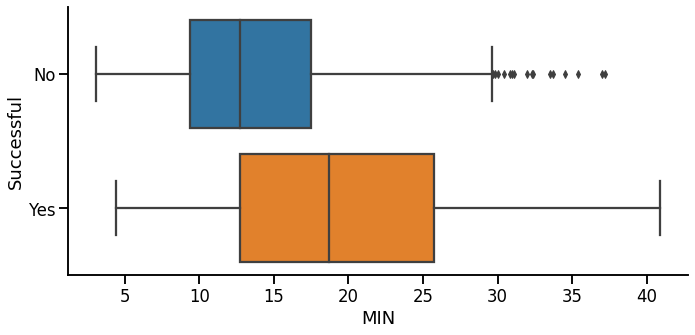

In [5]:
# Explore the differences between the successful and unsuccessful players

sns.catplot(data=nba_data, kind='box', x='MIN', y="Successful", aspect=2, height=5);

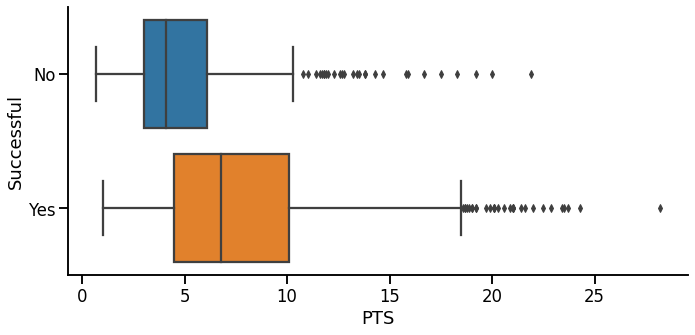

In [6]:
sns.catplot(data=nba_data, kind='box', x='PTS', y="Successful", aspect=2, height=5);

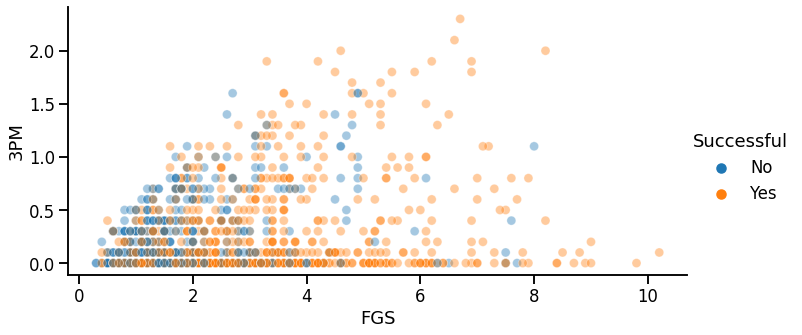

In [7]:
sns.relplot(data=nba_data, kind='scatter', x='FGS', y='3PM',hue="Successful", alpha=0.4, aspect =2); 

#players who score more 3 point shots and field goals tend to be more successful
#use scatter plots to show relationship between two numerical variables, box plots for relation between one categorical and one numerical

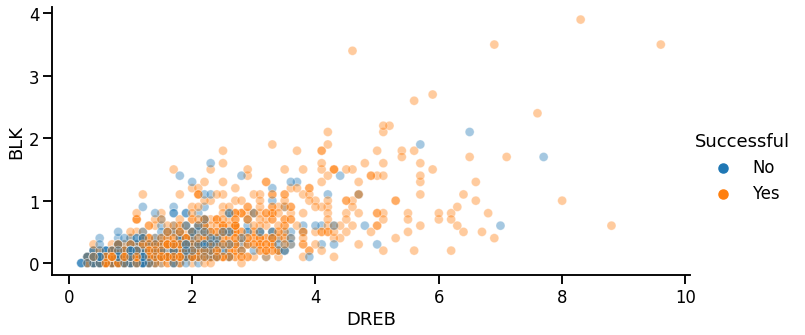

In [8]:
sns.relplot(data=nba_data, kind='scatter', x='DREB', y='BLK',hue="Successful", alpha=0.4, aspect =2); 

#players who block more shots and get more successful defensive reounds tend to be more successful

# Building a model (1): single input feature
## Building a model based on `PTS`

The code in the box below:

* Defines the input_features and target feature and creates an **80:20 training-testing split.**
* Creates the model using the training data: It finds the best value of the target features to split at using the `DecisionTreeClassifier().fit` command from the sklearn machine learning library with the number of splits determined by the value of `max_depth`. It displays the model as a decision tree using `plot_tree` from the matplotlib library.
* Creates a list of the predictions for the testing data using the model and displays the confusion matrix.

when using ML to build a model:
1. define your features; the input features, the output one, perform 'training and testing split' -> random 80% we use to train the model, then 20% we use to evaluate the model's predictions. 80/20 is a common split, but this could change depending on data size or type. 80/20 is definitely the standard
2. 
3. 

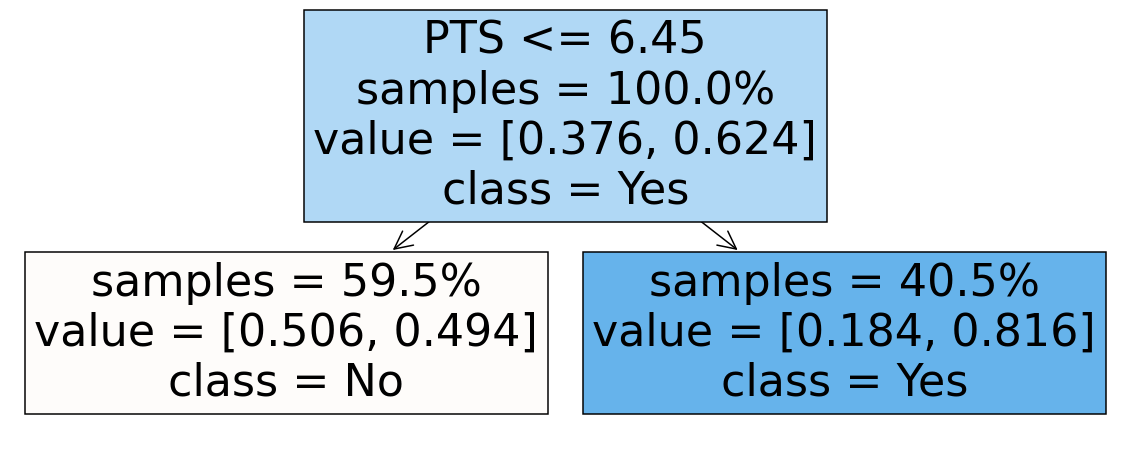

Predicted,0,1,All
Actual,,,
0,76,23,99
1,76,87,163
All,152,110,262


In [9]:
# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['PTS']
X = nba_data[input_features]
y = nba_data['5Yrs'] #numerical, not categorical binary feature
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1) 

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train) #.fit() is the code trying to fit it to a model
plot_decision_tree(tree_model)

# create a list of the predictions and calculate the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

**to start, we're going to focus only on the top line of the light blue box and the class="" bits of the bottom two boxes**

the way the above chart works is if PTS is less than or equal to 6.45, the statement is true and we go down to the left hand box. if its false, we go to the right hand box

the little table is called a **confusion matrix**: what it says is, of the 262 players in the testing set, the model predicted 76 people who were successful actually were, and predicted 23 who werent successful would be. 

<a id='explore'></a>
## Task 2: Building a model based on `GP`

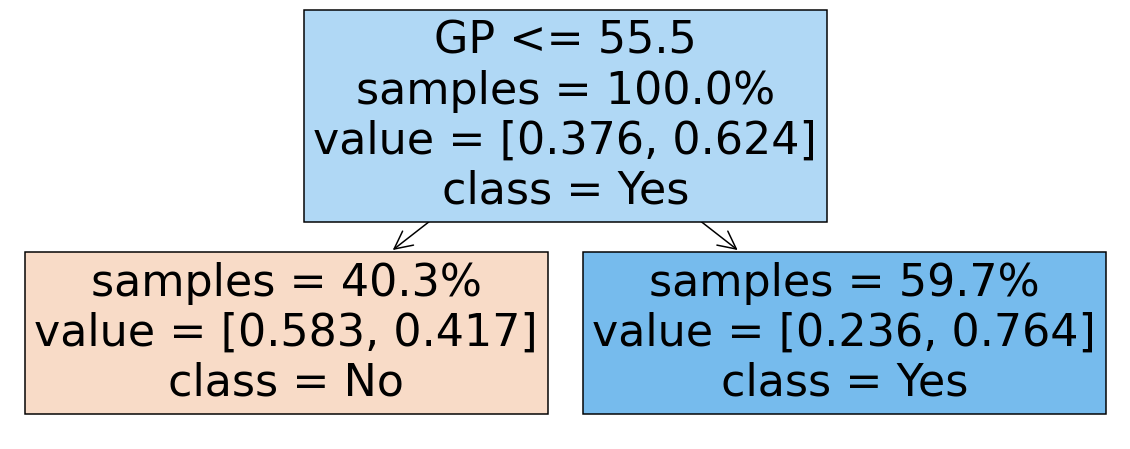

Predicted,0,1,All
Actual,,,
0,60,39,99
1,38,125,163
All,98,164,262


In [10]:
# copy the code for building a model with PTS and change this to GP

# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['GP']
X = nba_data[input_features]
y = nba_data['5Yrs'] #numerical, not categorical binary feature
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1) 

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train) #.fit() is the code trying to fit it to a model
plot_decision_tree(tree_model)

# create a list of the predictions and calculate the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

*Your model should misclassify 39 players as successful (who weren't successful) and 38 players as not successful (who were successful).*

## Building a model based on another feature

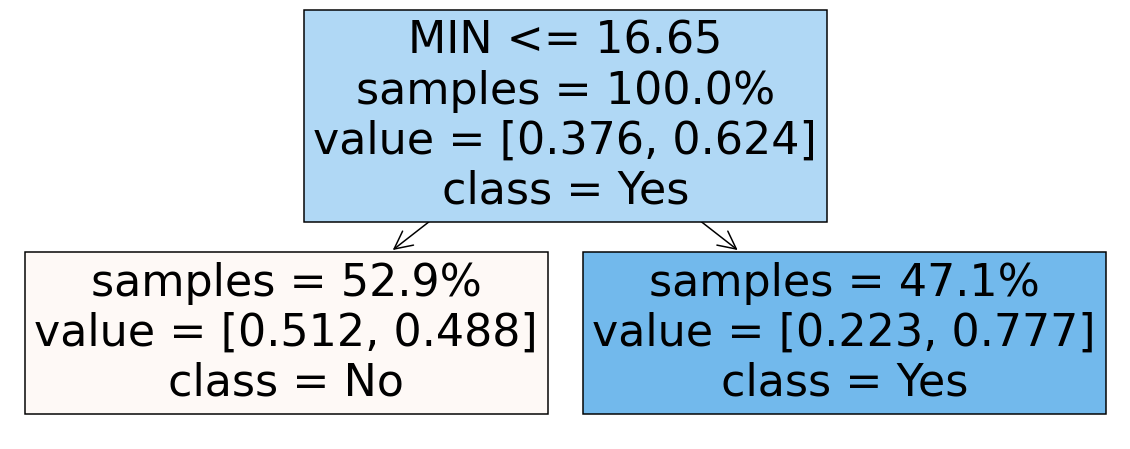

Predicted,0,1,All
Actual,,,
0,70,29,99
1,66,97,163
All,136,126,262


In [11]:
# copy the code for building a model with PTS and change this to GP

# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['MIN']
X = nba_data[input_features]
y = nba_data['5Yrs'] #numerical, not categorical binary feature
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1) 

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train) #.fit() is the code trying to fit it to a model
plot_decision_tree(tree_model)

# create a list of the predictions and calculate the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

this model based on mean minutes played struggles to predict failed players. it missclassifies a lot of successful players as unsuccessful

## Building a model based on another feature

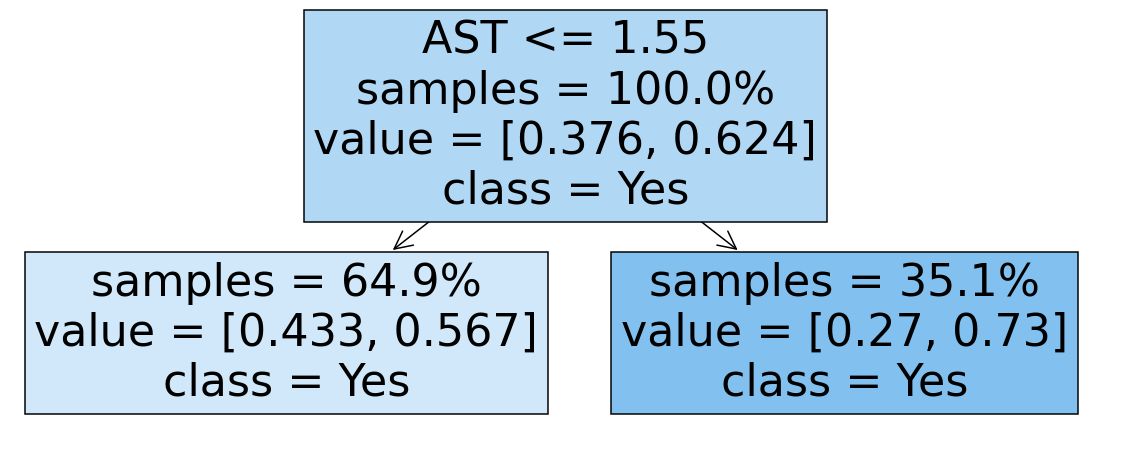

Predicted,1,All
Actual,,
0,99,99
1,163,163
All,262,262


In [12]:
# copy the code for building a model with PTS and change this to GP

# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['AST']
X = nba_data[input_features]
y = nba_data['5Yrs'] #numerical, not categorical binary feature
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1) 

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train) #.fit() is the code trying to fit it to a model
plot_decision_tree(tree_model)

# create a list of the predictions and calculate the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

sometimes, the confusion matrix doesnt have two columns. it predicts everyone as successful. this happens when both the bottom boxes are blue, basically because its found the optimum split, but has also found that more than half of players on each side of that split were successful

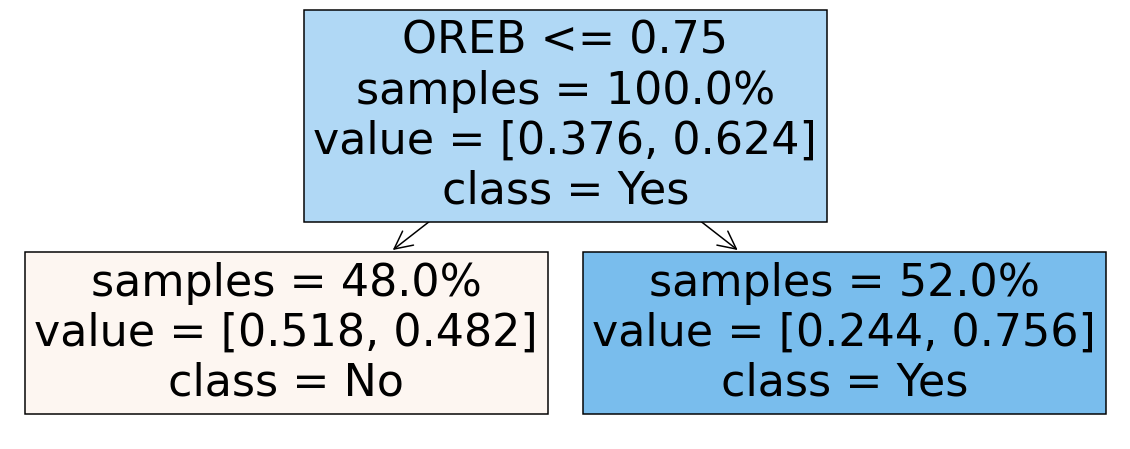

Predicted,0,1,All
Actual,,,
0,66,33,99
1,60,103,163
All,126,136,262


In [13]:
# copy the code for building a model with PTS and change this to GP

# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['OREB']
X = nba_data[input_features]
y = nba_data['5Yrs'] #numerical, not categorical binary feature
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1) 

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train) #.fit() is the code trying to fit it to a model
plot_decision_tree(tree_model)

# create a list of the predictions and calculate the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

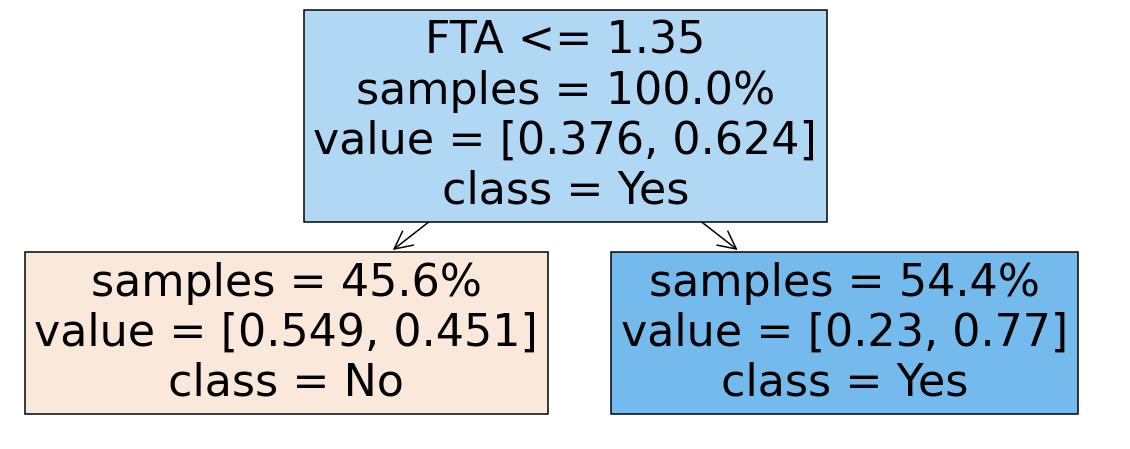

Predicted,0,1,All
Actual,,,
0,59,40,99
1,57,106,163
All,116,146,262


In [14]:
# copy the code for building a model with PTS and change this to GP

# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['FTA']
X = nba_data[input_features]
y = nba_data['5Yrs'] #numerical, not categorical binary feature
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1) 

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train) #.fit() is the code trying to fit it to a model
plot_decision_tree(tree_model)

# create a list of the predictions and calculate the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

# Building a model (2): multiple input features

## Task 3: Building a model based on `3PM` and `PTS`

Notice that the code below now has two values in the `input_features` line. <br>
The `max_depth` of the tree has also been increased to 2



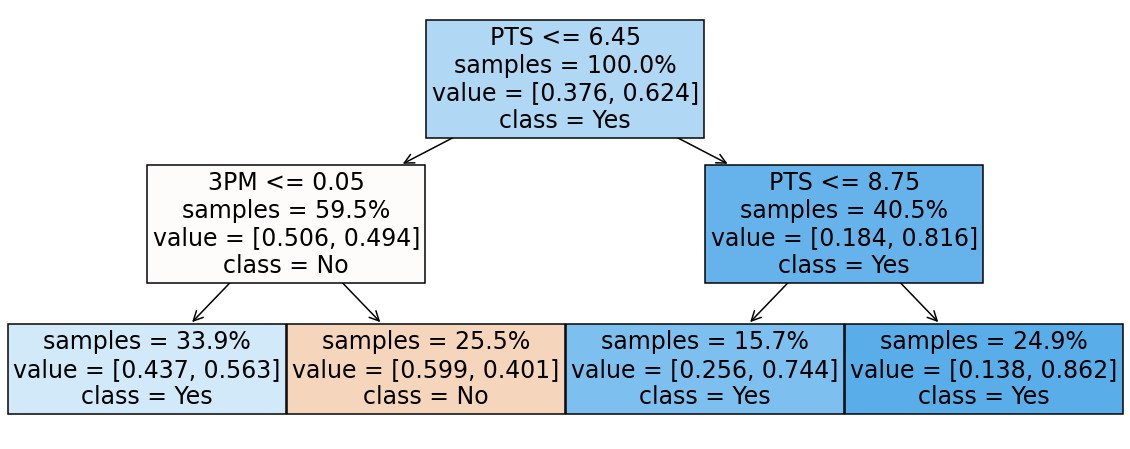

Predicted,0,1,All
Actual,,,
0,46,53,99
1,37,126,163
All,83,179,262


In [15]:
# define the input features create the input table (X) and define the target feature (y), perform the training-testing split
input_features = ['3PM','PTS'] #more input features can mean a better model
X = nba_data[input_features]
y = nba_data['5Yrs']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

fewer missclassifications, so arguably a better model? this will be discussed more in future lessons

## Building a model based on another pair of features

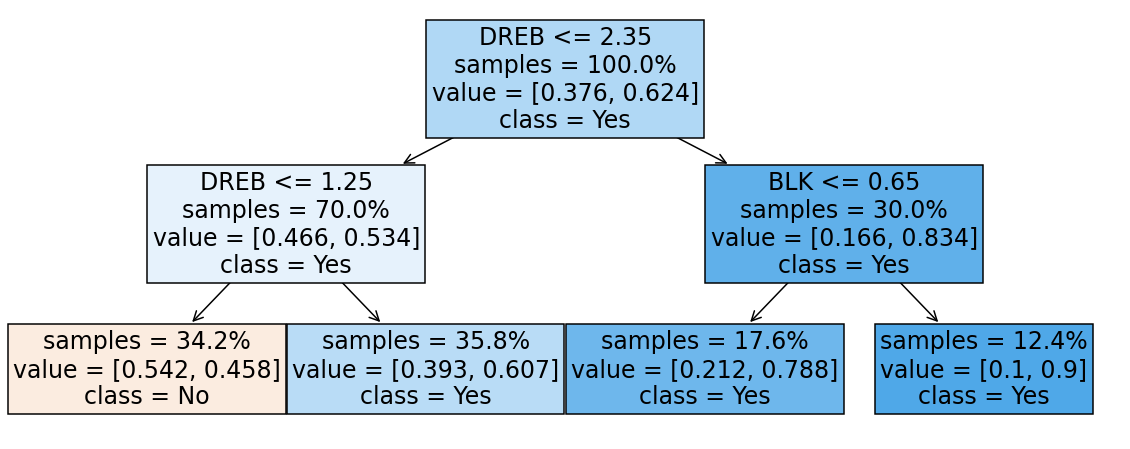

Predicted,0,1,All
Actual,,,
0,54,45,99
1,34,129,163
All,88,174,262


In [16]:
input_features = ['DREB','BLK'] #more input features can mean a better model
X = nba_data[input_features]
y = nba_data['5Yrs']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

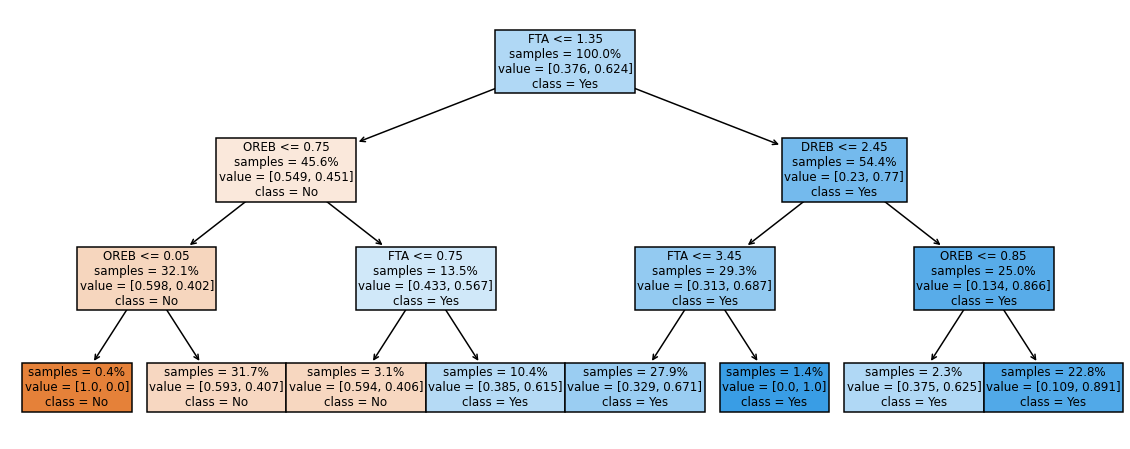

Predicted,0,1,All
Actual,,,
0,52,47,99
1,40,123,163
All,92,170,262


In [17]:
input_features = ["FTA","OREB","DREB"] #more input features can mean a better model
X = nba_data[input_features]
y = nba_data['5Yrs']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

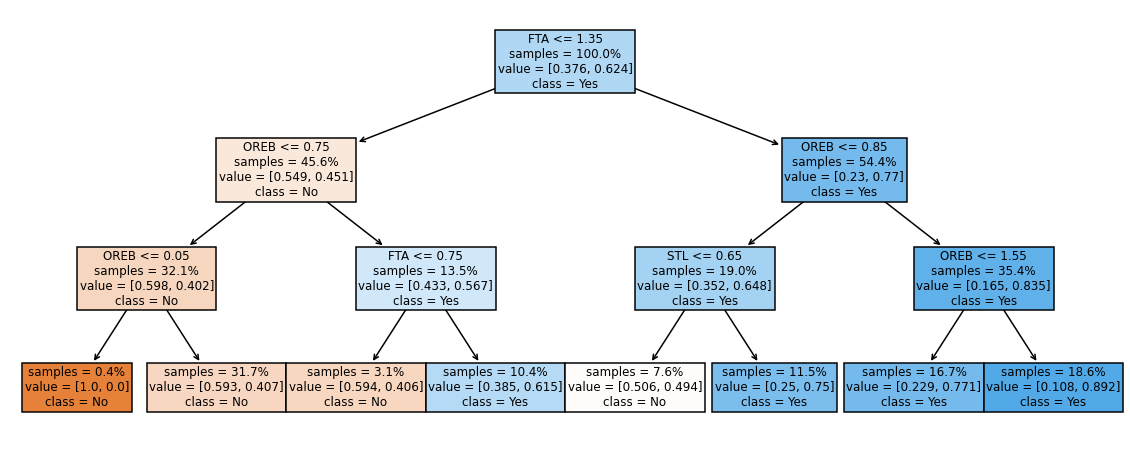

Predicted,0,1,All
Actual,,,
0,63,36,99
1,51,112,163
All,114,148,262


In [18]:
input_features = ["FTA","OREB","STL"] #more input features can mean a better model
X = nba_data[input_features]
y = nba_data['5Yrs']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

## Building a model based on another pair of features

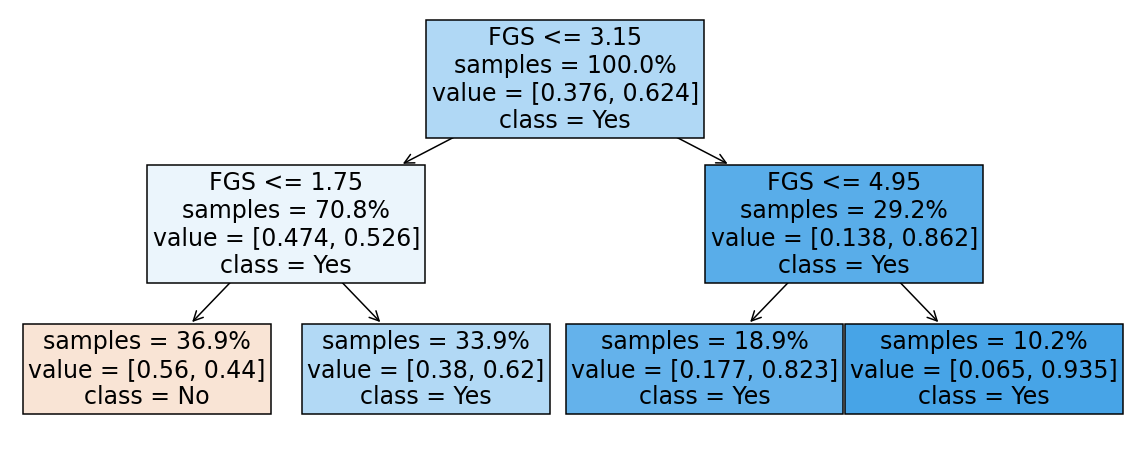

Predicted,0,1,All
Actual,,,
0,60,39,99
1,34,129,163
All,94,168,262


In [19]:
input_features = ["FGA","FGS"] #more input features can mean a better model
X = nba_data[input_features]
y = nba_data['5Yrs']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the decision tree
tree_model = DecisionTreeClassifier(max_depth=2).fit(X_train, y_train)
plot_decision_tree(tree_model)

# create a list of the predictions and display the metrics
y_pred = tree_model.predict(X_test)
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

<a id='plottree'></a>
# Appendix: Explaining the parameters for the plot_tree command

The code below shows explains the parameters used in the `plot_tree` command.

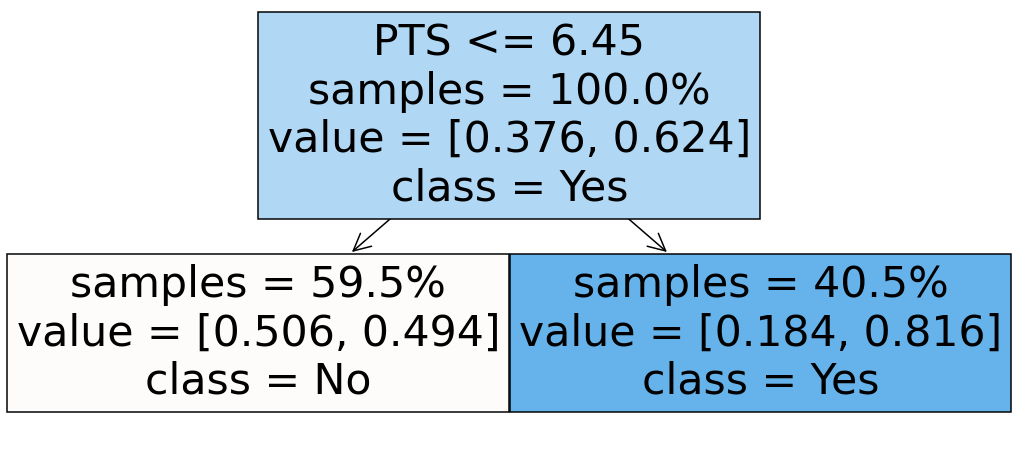

In [20]:
# Define the input and target data
input_features=['PTS']
input_data = nba_data[input_features]
target_data =  nba_data['5Yrs']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(input_data, target_data, train_size=0.8, random_state=1)

# Build the model. Try changing max_depth
tree_model = DecisionTreeClassifier(max_depth=1).fit(X_train, y_train)

# display the model
fig, ax = plt.subplots(figsize=(18,8)) # creates a figure with axes 
plot_tree(tree_model,  # name of the model to be plotted 
          filled=True,  # Stronger color represents lower node impurity (measured by gini coefficient) 
          feature_names=input_features, # Use feature names instead of numbers
          proportion=True, # Show the proportions of each class that reach the node
          impurity=False, # hide the impurity score
          class_names=["No", "Yes"], # Human readable labels, in ascending order of class numerical value
          ax=ax # plot the tree on the axes defined
         ); 